# Season contrasts: phase scoring, the shape of the acceleration, and the tail of innings totals

**The question, given the exploration.** The exploration showed 2024 scoring higher than 2023 at the innings level, with the rise concentrated in the powerplay and death overs, the powerplay six share up about 40% with wickets flat, pace displacing spin in every phase, and 220+ innings going from one in twenty to one in seven. Those were descriptive reads of the two seasons as they happened. This notebook asks which of them survive a proper accounting of noise: with about 70 matches per season, how much of each change could be the luck of the draw?

**What this notebook does.**
1. Puts every season contrast (phase run rates, powerplay six rate and wicket rate, pace share by phase, the controlled-power shot shift, a death spin economy check) through a match cluster bootstrap and reports an interval for each.
2. Tests "the ends accelerated while the middle lagged" as a single shape claim, with a pre-stated smallest effect worth caring about, so a null can be read as evidence of absence rather than absence of evidence.
3. Studies the tail of innings totals on the only population where totals are honest: first innings with a full allowance. A chasing side stops when it reaches the target, so its total says nothing about how much it could have scored.

**How to read this notebook.** A *match cluster bootstrap* rebuilds each season many times by drawing whole matches at random with replacement (never single balls, because balls within a match are not independent), recomputes the statistic each time, and reads the spread of those recomputations as the uncertainty. An *interval* here is the range containing 95% of those recomputations, built two ways: *bootstrap-t* (the primary for rates, using a closed-form standard error) and *BCa* (a bias- and skew-corrected percentile interval, the primary where no closed form exists). "Clears zero" means the interval does not contain the null value (zero for a difference, one for a ratio). Ratios are estimated on the log scale and converted back. All intervals are 95% unless stated.

**Numbers in the text.** The figures quoted below are from the run of 9 September 2026 under the seed in `config.toml`. Every run with that seed reproduces them; if a table above a paragraph ever disagrees with the paragraph, the table is current. Code lives in `scripts/mean_level_and_tail/`; this notebook orchestrates, displays and writes outputs with provenance sidecars.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from mean_level_and_tail.phase_shape_contrasts import run_shape_contrasts
from mean_level_and_tail.innings_tail import run_tail_analysis, plot_shift_function
from mean_level_and_tail import forest_plot
from mean_level_and_tail.regression_check import run_regression_check

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)

settings = load_settings()
ANALYSIS = "mean_level_and_tail"
SEED = settings.seed(ANALYSIS)
N_ITER = settings.n_resamples
PRODUCER = "mean_level_and_tail.ipynb"
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}  level={settings.interval_level}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  level=0.95


## Data

The cleaned two-season frame (`data/dpl_prelims_clean.parquet`, built by `data_validation.ipynb`). If it is absent, a schema-faithful synthetic fixture stands in so the pipeline can be exercised; every number is then mechanics only and nothing from it is a finding. `USING_FIXTURE` guards the cells that only make sense on real data.

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (mechanics only, no findings)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}  seasons={sorted(df['year'].unique())}")

rows=34,967  matches=145  seasons=[np.int64(2023), np.int64(2024)]


## Schema confirmations

Cheap checks that precede any rate, repeating the conventions the validation notebook established: over numbers run 1 to 20 (a zero-indexed export would shift every phase boundary), `wide` is a run count and `noball` a flag, byes and leg byes are populated so a dot ball must key off runs off the bat, the mixed or unknown bowler kind is a small mass, `target` is blank in the first innings, `control_clean` is present.

In [3]:
print("over_num range:", df["over_num"].agg(["min", "max"]).tolist())
display(df[["wide", "noball", "byes", "legbyes"]].describe().loc[["mean", "max"]])
display(df.groupby("year")["bowl_kind"].value_counts(normalize=True).round(4).unstack(fill_value=0))
print("outcome values:", sorted(df["outcome"].astype(str).unique()))
print("target NaN share, inns 1 / inns 2:",
      round(df.loc[df["inns"] == 1, "target"].isna().mean(), 3),
      round(df.loc[df["inns"] == 2, "target"].isna().mean(), 3))
print("control_clean present:", "control_clean" in df.columns)
print("max_balls below 120 anywhere (innings):",
      int((df.groupby(["p_match", "inns"])["max_balls"].min() < 120).sum()))

over_num range: [1, 20]


,wide,noball,byes,legbyes
mean,0.0455,0.005005,0.004919,0.018189
max,5.0000,1.000000,4.000000,4.000000


bowl_kind,mixture/unknown,pace bowler,spin bowler
year,,,
2023,0.0030,0.5895,0.4075
2024,0.0004,0.6724,0.3273


outcome values: ['bye', 'four', 'leg bye', 'no ball', 'no run', 'out', 'run', 'six', 'wide']
target NaN share, inns 1 / inns 2: 1.0 0.0
control_clean present: True
max_balls below 120 anywhere (innings): 4


## Season contrasts, one shared set of draws

Every contrast below is computed on the same 10,000 match resamples, so contrasts that share matches keep their correlation and can be read jointly. Columns: `estimate`; `ci_low` and `ci_high` with `interval_method` naming the primary construction; the bootstrap-t and BCa intervals always shown side by side; for ratios also the BCa interval computed on the raw ratio scale; the closed-form cluster standard error `se_linearized`; a flag if the log-ratio bootstrap bias is large. The two all-innings tail rows at the bottom pool chases with first innings and are superseded by the tail section; they stay in the table for continuity with the regression check at the end.

In [4]:
theme_table, theme_results = scb.run_all(df, n_iter=N_ITER, seed=SEED,
                                         alpha=1.0 - settings.interval_level, return_results=True)
results_io.write_table(theme_table, settings, ANALYSIS, "theme_contrasts", SEED, PRODUCER,
                       extra={"n_resamples": N_ITER, "fixture": USING_FIXTURE})
theme_table

,theme,estimate,ci_low,ci_high,interval_method,bca_low,bca_high,boot_t_low,boot_t_high,raw_scale_bca_low,raw_scale_bca_high,null,resampling_stable,se_boot,se_linearized,log_ratio_bias,log_ratio_bias_flag,scale,interval_level,power_tier,note
0,powerplay_six_rate_ratio,1.3898,1.1353,1.7002,bootstrap_t,1.1477,1.7072,1.1353,1.7002,1.1475,1.7069,1.0,True,0.10162,0.10241,-0.00250,False,log,0.95,well_powered,Aerial aggression up top. Pair with the wicket-cost theme below.
1,powerplay_wicket_rate_diff,0.0042,-0.0027,0.0110,bootstrap_t,-0.0025,0.0110,-0.0027,0.0110,NaN,NaN,0.0,False,0.00346,0.00346,NaN,False,linear,0.95,well_powered,"Cost side of the aggression claim. Straddling zero is the finding,..."
2,powerplay_run_rate_diff,0.7279,0.1845,1.3533,bootstrap_t,0.2076,1.3563,0.1845,1.3533,NaN,NaN,0.0,True,0.28832,0.28970,NaN,False,linear,0.95,well_powered,"Runs per over, legal balls only."
3,middle_run_rate_diff,0.3642,-0.1940,0.9419,bootstrap_t,-0.2026,0.9258,-0.1940,0.9419,NaN,NaN,0.0,False,0.28341,0.28411,NaN,False,linear,0.95,well_powered,"Runs per over, legal balls only."
4,death_run_rate_diff,0.6849,-0.0160,1.4343,bootstrap_t,-0.0229,1.4070,-0.0160,1.4343,NaN,NaN,0.0,False,0.36446,0.36566,NaN,False,linear,0.95,well_powered,"Runs per over, legal balls only."
5,bookending_powerplay_vs_middle,0.3637,-0.2685,1.0384,bootstrap_t,-0.2510,1.0326,-0.2685,1.0384,NaN,NaN,0.0,False,0.32795,0.33122,NaN,False,linear,0.95,composite,"Shape test. Wide interval means bookending is suggestive, not that..."
6,bookending_death_vs_middle,0.3208,-0.3491,1.0234,bootstrap_t,-0.3395,1.0092,-0.3491,1.0234,NaN,NaN,0.0,False,0.34448,0.35073,NaN,False,linear,0.95,composite,Second leg of the bookended-acceleration shape.
7,pace_share_diff_powerplay,0.0623,0.0206,0.1026,bootstrap_t,0.0214,0.1023,0.0206,0.1026,NaN,NaN,0.0,True,0.02062,0.02084,NaN,False,linear,0.95,well_powered,"League and phase level. Per-team pace shift is texture, not tested..."
8,pace_share_diff_middle,0.1025,0.0583,0.1459,bootstrap_t,0.0599,0.1454,0.0583,0.1459,NaN,NaN,0.0,True,0.02223,0.02267,NaN,False,linear,0.95,well_powered,"League and phase level. Per-team pace shift is texture, not tested..."
9,pace_share_diff_death,0.0770,0.0322,0.1215,bootstrap_t,0.0323,0.1195,0.0322,0.1215,NaN,NaN,0.0,True,0.02223,0.02245,NaN,False,linear,0.95,well_powered,"League and phase level. Per-team pace shift is texture, not tested..."


Four contrasts clear zero and one does not, and the one that does not is the most important.

- Powerplay six rate: 1.39 times the 2023 rate, interval 1.14 to 1.70. The single strongest change in the data.
- Powerplay wicket rate: +0.4 wickets per hundred balls, interval −0.3 to +1.1. It straddles zero. The extra sixes did not come with a measurable wicket cost; that pairing is the headline of the whole project, and its wicket half is tested further in `expected_wickets.ipynb`.
- Powerplay run rate: +0.73 runs per over, interval 0.18 to 1.35. Middle (+0.36) and death (+0.68) rose by similar amounts as points but their intervals reach below zero, so they are directional, not established.
- Pace share rose in every phase and clears zero in each: +6 points in the powerplay, +10 in the middle, +8 at the death. The middle-overs shift is the largest, matching the exploration.
- Controlled-power shots (pull, hook, upper cut) gained about 3 points of shot share on the slog, interval 1.7 to 4.0, with the caveat that shot labels are manual.
- Death spin economy rose 2.2 runs per over, interval 0.7 to 3.7, but on a shrinking and self-selected set of balls (teams bowled less spin at the death), so it describes what happened to the spin that was bowled, not what spin would have cost.

The two interval constructions agree to the second decimal everywhere, which is what the coverage simulation (`interval_coverage.ipynb`) says should happen at 70 matches per season.

## Precision guard

Legal balls per team in each phase, by season. A team-level spread (used in `dispersion_and_attribution.ipynb`) is sensitive to a change in how precisely each team's rate is estimated, so this is recorded before any team-level claim is made. Found: about 500 powerplay, 750 middle and 375 death balls per team per season, similar in both seasons.

In [5]:
for name in ("powerplay", "middle", "death"):
    for year in (settings.earlier_season, settings.later_season):
        counts = scb.balls_per_team_in_phase(df[df["year"] == year], settings.phase(name))
        print(f"{name:10s} {year}: min={counts.min()}  median={int(counts.median())}  max={counts.max()}")

powerplay  2023: min=504  median=504  max=612
powerplay  2024: min=432  median=504  max=576
middle     2023: min=718  median=756  max=911
middle     2024: min=648  median=756  max=832
death      2023: min=341  median=395  max=446
death      2024: min=269  median=374  max=415


## The resample distribution behind one interval

The 10,000 recomputations behind the powerplay six-rate interval, on the log scale it is estimated on. This is what an interval summarises: the black line is the null (a ratio of one), the orange line the median of the draws. Change `INSPECT` to look at any other contrast.

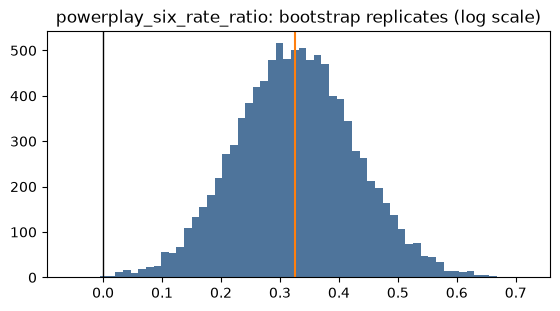

In [6]:
INSPECT = "powerplay_six_rate_ratio"
r = next(t for t in theme_results if t.name == INSPECT)
reps = r.replicates[np.isfinite(r.replicates)]
null = np.log(r.null_value) if r.scale == "log" else r.null_value
plt.figure(figsize=(6.5, 3.2))
plt.hist(reps, bins=60, color="#2F5C8A", alpha=0.85)
plt.axvline(null, color="k", lw=1)
plt.axvline(np.median(reps), color="C1")
plt.title(f"{INSPECT}: bootstrap replicates ({r.scale} scale)")
plt.show()

## Did the ends accelerate while the middle lagged?

**Question.** The exploration read the phase changes as a barbell: powerplay and death up by about 0.75 runs per over, the middle by half that. Read as three separate numbers with their intervals, all three overlap, so the shape claim has to be tested as one statistic.

**Method.** A *curvature contrast* weights the three phase changes +1 (powerplay), −2 (middle), +1 (death); it is positive when the ends moved more than the middle, and zero if all three moved alike. It is computed in three channels: boundary share and six share (dense, thousands of balls per phase) and run rate. A second contrast tests the middle overs directly against the whole-innings change. All four read the same match resamples as the section above.

Because a null result only means something against a stated size, each contrast gets an *equivalence verdict*: `rejects_null` if the 95% interval excludes zero; `equivalent_to_zero` if the 90% interval sits entirely inside a band of effects too small to matter (the SESOI, set in `config.toml` before the run: 0.5 runs per over, 1.5 points of boundary share, 0.75 points of six share); `inconclusive` otherwise. The table also gives the minimum detectable effect at 80% power, so an inconclusive verdict can be read as "could not have been detected" when that number exceeds the SESOI. The hypothesis is retired only if both dense channels are equivalent to zero.

In [7]:
shape_table, shape_verdicts = run_shape_contrasts(df, settings, SEED, n_iter=N_ITER)
results_io.write_table(shape_table, settings, ANALYSIS, "shape_contrasts", SEED, PRODUCER,
                       extra={"n_resamples": N_ITER, "fixture": USING_FIXTURE})
results_io.write_table(shape_verdicts, settings, ANALYSIS, "shape_contrast_verdicts", SEED, PRODUCER,
                       extra={"n_resamples": N_ITER, "fixture": USING_FIXTURE,
                              "sesoi": settings.section("sesoi"),
                              "hypothesis_status": shape_verdicts.attrs["hypothesis_status"]})
print("bookended-acceleration hypothesis:", shape_verdicts.attrs["hypothesis_status"])
display(shape_table[["theme", "estimate", "ci_low", "ci_high", "interval_method", "se_linearized", "resampling_stable"]])
shape_verdicts.round(4)

bookended-acceleration hypothesis: unresolved


,theme,estimate,ci_low,ci_high,interval_method,se_linearized,resampling_stable
0,middle_rpo_minus_league_rpo,-0.1728,-0.4539,0.1057,bootstrap_t,0.14304,False
1,bookending_curvature_boundary,0.0238,-0.0142,0.0601,bootstrap_t,0.01855,False
2,bookending_curvature_six,0.0140,-0.0110,0.0399,bootstrap_t,0.01291,False
3,bookending_curvature_rpo,0.6844,-0.3556,1.7238,bootstrap_t,0.52772,False


,channel,estimate,ci90_low,ci90_high,ci95_low,ci95_high,se,sesoi,mde_80pct_power,mde_exceeds_sesoi,verdict,unit,interval_method
0,middle_rpo_minus_league_rpo,-0.1728,-0.4075,0.0642,-0.4539,0.1057,0.1430,0.50,0.4005,False,equivalent_to_zero,runs per over,bootstrap_t
1,bookending_curvature_boundary,2.3822,-0.7482,5.4136,-1.4240,6.0143,1.8552,1.50,5.1946,True,inconclusive,percentage points,bootstrap_t
2,bookending_curvature_six,1.4010,-0.6892,3.5801,-1.0985,3.9893,1.2915,0.75,3.6162,True,inconclusive,percentage points,bootstrap_t
3,bookending_curvature_rpo,0.6844,-0.1835,1.5467,-0.3556,1.7238,0.5277,0.50,1.4776,True,inconclusive,runs per over,bootstrap_t


No contrast clears zero, and only one is equivalent to zero: the middle-against-league run rate, at −0.17 runs per over with a 90% interval of −0.41 to +0.06, inside the ±0.5 band. The curvature contrasts all lean positive (+2.4 points of boundary share, +1.4 of six share, +0.68 runs per over) with intervals that include zero, and in each case the minimum detectable effect (5.2, 3.6 and 1.5) is about three times the SESOI. The barbell is therefore *unresolved*: the middle overs did not lag the league as a whole by a meaningful amount, and the test of whether the ends rose more than the middle could not resolve an effect of the size that would matter. The acceleration was broad; whether it was larger at the ends could not be determined at this sample size.

## The tail of innings totals

**Question.** The exploration's most striking number was 220+ innings going from one in twenty to one in seven. But that pooled all innings, and a chasing side stops when it reaches its target: a successful chase of 150 is a total of 150 whatever the side could have scored. Early chase finishes rose across the seasons, which by itself moves the upper quantiles of a pooled distribution. So the question is asked on first innings with a full 120-ball allowance, where the total is what the side actually made. Failed chases (the chasing side fell short, so its innings ran its course) are added as a sensitivity population.

**Method.** The 220+ share as a 2×2 table (season by at-or-above 220) with a *risk difference* (the change in the share) and a Newcombe score interval, which behaves well at small counts, plus Fisher's exact test; the match-bootstrap ratio as a secondary check. A *shift function*: the change in the innings-total quantile at 0.5, 0.6, 0.7, 0.8 and 0.9, each with a BCa interval, showing where in the distribution the change sits. The 95th and 97th percentiles are not reported as findings because with 70 innings they are set by three or four scores; they are kept in an appendix table. Exceedance at 180, 200 and 220 with the same 2×2 machinery, and a generalized Pareto fit to the excesses above 180 (a standard model for the tail of a distribution) giving a model-based 220+ probability per season.

In [8]:
tail = run_tail_analysis(df, settings, SEED, n_iter=N_ITER)
tail_extra = {"n_resamples": N_ITER, "fixture": USING_FIXTURE, "tail": settings.section("tail")}
results_io.write_table(tail["population_counts"], settings, ANALYSIS, "tail_population_counts", SEED, PRODUCER, tail_extra)
results_io.write_table(tail["innings_table"], settings, ANALYSIS, "tail_innings_table", SEED, PRODUCER, tail_extra)
results_io.write_table(tail["threshold_contrasts"], settings, ANALYSIS, "tail_threshold_contrasts", SEED, PRODUCER, tail_extra)
results_io.write_table(tail["share_ratio_bootstrap"], settings, ANALYSIS, "tail_share_ratio_bootstrap", SEED, PRODUCER, tail_extra)
results_io.write_table(tail["shift_function"], settings, ANALYSIS, "tail_shift_function", SEED, PRODUCER, tail_extra)
results_io.write_table(tail["sparse_upper_quantile_shifts"], settings, ANALYSIS, "tail_sparse_upper_quantile_shifts", SEED, PRODUCER, tail_extra)
results_io.write_json(tail["gpd"], settings, ANALYSIS, "tail_gpd", SEED, PRODUCER, tail_extra)
display(tail["population_counts"])
tail["threshold_contrasts"].round(4)

,year,dls_reduced,failed_chase,first_innings,successful_chase,first_innings_all_out_before_death
0,2023,2,40,74,31,0
1,2024,2,34,70,36,0


,threshold,n_earlier,over_earlier,n_later,over_later,share_later,share_earlier,risk_difference,rd_low,rd_high,fisher_exact_p,population,headline
0,180,74,40,70,40,0.5714,0.5405,0.0309,-0.1286,0.1878,0.7395,first_innings_full_allowance,False
1,200,74,24,70,26,0.3714,0.3243,0.0471,-0.1063,0.1983,0.6016,first_innings_full_allowance,False
2,220,74,7,70,13,0.1857,0.0946,0.0911,-0.0238,0.2080,0.1490,first_innings_full_allowance,True
3,180,114,52,104,58,0.5577,0.4561,0.1016,-0.0308,0.2290,0.1389,first_innings_plus_failed_chases,False
4,200,114,29,104,35,0.3365,0.2544,0.0822,-0.0385,0.2009,0.2335,first_innings_plus_failed_chases,False
5,220,114,7,104,18,0.1731,0.0614,0.1117,0.0264,0.2013,0.0109,first_innings_plus_failed_chases,True


**Population.** 74 and 70 first innings with a full allowance, two DLS-reduced innings per season, 31 and 36 successful chases, 40 and 34 failed chases, no first innings all out before the death. The primary population is about half the innings; that is the honest count, and it is why the intervals below are wide.

In [9]:
display(tail["share_ratio_bootstrap"][["population", "theme", "estimate", "ci_low", "ci_high",
                                       "interval_method", "log_ratio_bias", "log_ratio_bias_flag"]])
tail["shift_function"][["population", "quantile", "estimate", "ci_low", "ci_high", "interval_method"]]

,population,theme,estimate,ci_low,ci_high,interval_method,log_ratio_bias,log_ratio_bias_flag
0,first_innings_full_allowance,innings_220_plus_share_ratio,1.9633,0.7929,5.2857,bca,0.03188,False
1,first_innings_plus_failed_chases,innings_220_plus_share_ratio,2.8187,1.1880,7.5974,bca,0.03235,False


,population,quantile,estimate,ci_low,ci_high,interval_method
0,first_innings_full_allowance,0.5,2.5,-14.0000,17.5000,bca
1,first_innings_full_allowance,0.6,4.4,-10.8000,20.0000,bca
2,first_innings_full_allowance,0.7,6.6,-6.5000,19.2000,bca
3,first_innings_full_allowance,0.8,6.0,-8.0000,21.4000,bca
4,first_innings_full_allowance,0.9,17.9,-3.0000,49.2000,bca
5,first_innings_plus_failed_chases,0.5,5.5,-8.0000,18.0000,bca
6,first_innings_plus_failed_chases,0.6,10.0,-3.6000,23.0000,bca
7,first_innings_plus_failed_chases,0.7,5.2,-6.8000,16.8419,bca
8,first_innings_plus_failed_chases,0.8,11.6,-1.4638,28.8000,bca
9,first_innings_plus_failed_chases,0.9,20.7,3.2000,49.4725,bca


In [14]:
import json
tail["sparse_upper_quantile_shifts"][["population", "theme", "estimate", "ci_low", "ci_high"]]

,population,theme,estimate,ci_low,ci_high
0,first_innings_full_allowance,sparse_upper_quantile_shift_q90,17.90,-3.000,49.2000
1,first_innings_full_allowance,sparse_upper_quantile_shift_q95,36.40,7.000,59.0000
2,first_innings_full_allowance,sparse_upper_quantile_shift_q97,39.53,8.531,60.1900
3,first_innings_plus_failed_chases,sparse_upper_quantile_shift_q90,20.70,3.200,49.4725
4,first_innings_plus_failed_chases,sparse_upper_quantile_shift_q95,36.35,10.750,58.0000
5,first_innings_plus_failed_chases,sparse_upper_quantile_shift_q97,38.03,13.670,59.5982


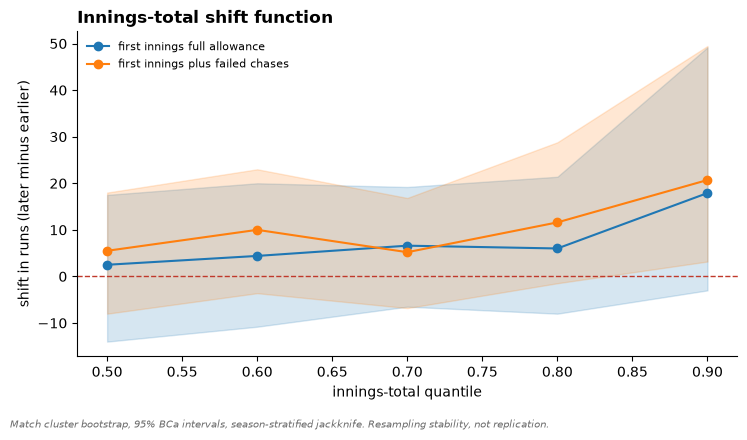

In [11]:
fig = plot_shift_function(tail["shift_function"], settings.interval_level)
results_io.write_figure(fig, settings, ANALYSIS, "tail_shift_function", SEED, PRODUCER)
plt.show()

On first innings the 220+ share rose from 9.5% (7 of 74) to 18.6% (13 of 70): a risk difference of +9 points with an interval of −2 to +21 and a Fisher p-value of 0.15. The bootstrap ratio is 2.0, interval 0.8 to 5.3. So on the population where the comparison is fair, the doubling of very high scores is directional, not established. Adding failed chases (114 and 104 innings) gives +11 points, interval +3 to +20, Fisher p 0.011, and a ratio of 2.8, interval 1.2 to 7.6, which does clear. The shift function tells the same story: the median moved 2.5 runs and the 90th percentile 18 runs, with every interval including zero on the primary population, and the 80th and 90th percentiles clearing (+12 and +21 runs) only with failed chases included. The generalized Pareto fit puts the 220+ probability at 12% in 2023 and 22% in 2024, a difference of +10 points with an interval of −2 to +23 on first innings and +1 to +21 with failed chases.

On first innings, the share of 220+ totals roughly doubled, from about one in ten to one in five; the change is large but the interval on 144 innings does not exclude zero. Including failed chases, which are also uncensored, it does. The pooled figure of "one in twenty to one in seven" overstated the change because it counted chases cut short at their target.

## The contrasts that survive, in one figure

Every contrast whose interval excludes its null, panelled by unit, with the first-innings 220+ risk difference appended. The stability flag chooses the rows; nothing is hand-picked, so a rerun that loses a contrast drops it from the figure.

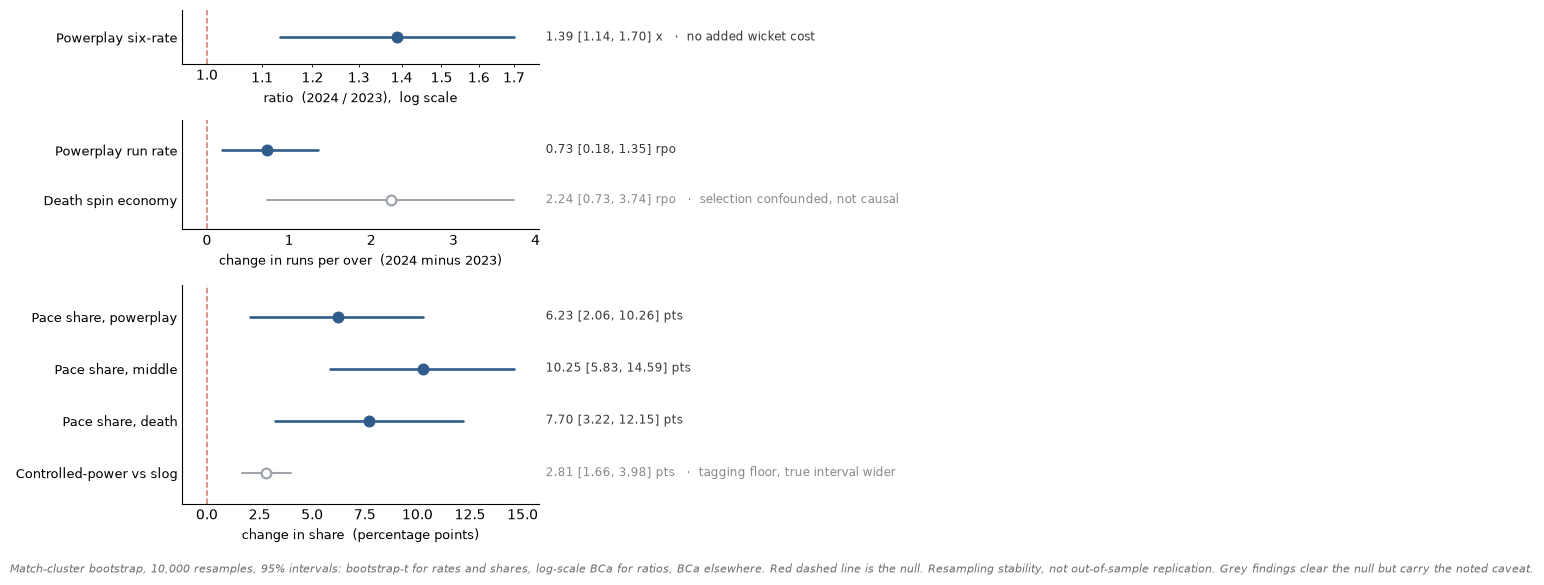

In [18]:
headline = tail["threshold_contrasts"].query(
    "headline and population == 'first_innings_full_allowance'").iloc[0].to_dict()
combined = pd.concat([theme_table, pd.DataFrame([forest_plot.risk_difference_row(headline)])],
                     ignore_index=True)
fig, _ = forest_plot.draw_forest(forest_plot.rows_from_results(combined), "",
                                 N_ITER, settings.interval_level)
results_io.write_figure(fig, settings, ANALYSIS, "resampling_stable_findings", SEED, PRODUCER)
plt.show()

## Regression check against a stored run

The estimands here were first built in an earlier notebook whose results were stored. The interval machinery has changed since (season-stratified jackknife, bootstrap-t, log-scale ratios) but the estimands have not. This cell reproduces the stored table with its original seeds and the pooled jackknife; every point estimate and every stored interval must match exactly, and the `stratified_*` columns show how far each interval moves under the current construction on the same draws. Found: all 22 rows match exactly; the stratified jackknife moves the quantile and spread intervals by a few runs or hundredths and everything else by zero.

In [13]:
if USING_FIXTURE:
    print("skipped: the reference numbers are from the real data")
else:
    regression = run_regression_check(df, settings, n_iter=10000)
    results_io.write_table(regression, settings, ANALYSIS, "regression_check", SEED, PRODUCER,
                           extra={"reference": "reference_previous_run.csv", "stored_run_seeds": [36, 20240601]})
    print("all points match:", bool(regression["estimate_matches"].all()),
          "| all stored intervals match:", bool(regression["interval_matches"].all()))
    display(regression)

all points match: True | all stored intervals match: True


,source,theme,stored_estimate,reproduced_estimate,estimate_matches,stored_ci_low,stored_ci_high,pooled_jackknife_bca_low,pooled_jackknife_bca_high,interval_matches,stratified_bca_low,stratified_bca_high,stratified_shift_low,stratified_shift_high
0,run_all,powerplay_six_rate_ratio,1.3898,1.3898,True,1.1370,1.7010,1.1370,1.7010,True,1.1370,1.7010,-0.0000,-0.0000
1,run_all,powerplay_wicket_rate_diff,0.0042,0.0042,True,-0.0024,0.0109,-0.0024,0.0109,True,-0.0024,0.0109,0.0000,0.0000
2,run_all,powerplay_run_rate_diff,0.7279,0.7279,True,0.2043,1.3411,0.2043,1.3411,True,0.2043,1.3411,-0.0000,-0.0000
3,run_all,middle_run_rate_diff,0.3642,0.3642,True,-0.1816,0.9175,-0.1816,0.9175,True,-0.1816,0.9175,-0.0000,-0.0000
4,run_all,death_run_rate_diff,0.6849,0.6849,True,-0.0053,1.4010,-0.0053,1.4010,True,-0.0054,1.4010,-0.0000,-0.0000
5,run_all,bookending_powerplay_vs_middle,0.3637,0.3637,True,-0.2582,1.0315,-0.2582,1.0315,True,-0.2582,1.0315,0.0000,0.0000
6,run_all,bookending_death_vs_middle,0.3208,0.3208,True,-0.3463,1.0114,-0.3463,1.0114,True,-0.3463,1.0113,-0.0000,-0.0000
7,run_all,pace_share_diff_powerplay,0.0623,0.0623,True,0.0194,0.1013,0.0194,0.1013,True,0.0194,0.1013,-0.0000,-0.0000
8,run_all,pace_share_diff_middle,0.1025,0.1025,True,0.0573,0.1469,0.0573,0.1469,True,0.0573,0.1469,-0.0000,-0.0000
9,run_all,pace_share_diff_death,0.0770,0.0770,True,0.0349,0.1214,0.0349,0.1214,True,0.0349,0.1214,0.0000,0.0000
